# 딥러닝 응용 과제1 - 프로그래밍 B. 인코더-디코더(U-Net)를 직접 쌓아 Oxford-IIIT Pet 분할하기

교재 5.4절(`5_4.ipynb`, [프로그램 5-6]~[프로그램 5-10])에서는 **직접 그린 도형(원·사각형)** 을
**2단짜리 `UNetMini`** 로 분할했습니다. 입력과 정답이 같은 장난감 문제였습니다.
이 노트북에서는 유명한 실제 데이터셋 **Oxford-IIIT Pet**(고양이·개 사진 7,349장 + 픽셀 단위 정답 마스크)을
직접 내려받고, **4단짜리 U-Net**을 직접 쌓아 "사진 → 반려동물 영역 마스크"를 학습합니다.

섹션 번호는 교재와 1:1로 대응됩니다.

| 이 노트북 | 교재 5_4.ipynb | 내용 |
| --- | --- | --- |
| [B-1] | [프로그램 5-6] | 분할 데이터셋 만들기 (실제 데이터 내려받기) |
| [B-2] | [프로그램 5-7] | U-Net 모델 직접 구성하기 |
| [B-3] | [프로그램 5-8] | 손실 함수와 옵티마이저 |
| [B-4] | [프로그램 5-9] | 학습 루프 실행하기 |
| [B-5] | (추가) | 학습 곡선 그리기 |
| [B-6] | [프로그램 5-10] | 분할 결과 시각화하기 |
| [B-7] | (추가) | 내 사진으로 분할해 보기 |

**과제 규칙**
- 이 노트북에는 `your code here`로 표시된 빈칸이 **10곳** 있습니다. 힌트 주석을 읽고 빈칸을 채우세요. 빈칸 밖의 코드는 고치지 않아도 됩니다.
- 모두 채우고 **런타임 → 모두 실행** 했을 때 저장소 `preview/` 폴더의 그림(프로그래밍B_UNet_page*.jpg)과 같은 형태의 결과가 나와야 합니다 (그림은 예시이며, 실제로는 반려동물 사진이 나옵니다).
- 교재 5_4.ipynb의 같은 번호 [프로그램]을 옆에 두고 보면 대부분의 빈칸을 채울 수 있습니다.

**실행 방법**
1. 메뉴 **런타임 → 런타임 유형 변경 → T4 GPU** 를 반드시 고르세요 (CPU는 매우 느립니다).
2. 바로 아래 **실험 설정** 셀의 값을 확인하고 **런타임 → 모두 실행** (데이터 내려받기 2~3분 + 학습 3~5분).
3. 서술형 과제를 할 때는 설정 셀의 값만 바꾼 뒤 다시 **모두 실행** 하고 결과를 비교하세요.

In [1]:
# ── 실험 설정 (이 셀의 값을 바꿔 가며 실험하세요) ─────────────────────────
IMG_SIZE   = 128      # 이미지·마스크를 이 크기(정사각형)로 줄여서 사용. 예: 64, 128, 256  (8의 배수)
N_TRAIN    = None     # 학습에 쓸 이미지 수. None이면 전부(3,680장). 예: 500
N_TEST     = 500      # 평가에 쓸 이미지 수 (최대 3,669장)
BATCH_SIZE = 16

BASE_CH    = 16       # U-Net 첫 단계의 채널 수. 단계마다 2배씩 늘어남 (16 → 32 → 64 → 128). 예: 8, 16, 32
N_POOL     = 3        # U-Net 풀링 횟수(깊이). IMG_SIZE가 2**N_POOL로 나누어떨어져야 함. 예: 2, 3, 4
USE_SKIP   = True     # 스킵 연결(인코더 특징을 디코더에 이어 붙이기) 사용 여부
USE_BN     = True     # 합성곱 뒤 배치 정규화(BatchNorm) 사용 여부

LR         = 1e-3     # 학습률
EPOCHS     = 5        # 학습 에폭 수
SEED       = 0

## [B-1] Oxford-IIIT Pet 분할 데이터셋 만들기 (교재 [프로그램 5-6] 대응)

교재는 `generate_shape_image()`로 도형을 그려 `ShapeDataset`을 만들었습니다. 여기서는 `torchvision.datasets.OxfordIIITPet`으로
실제 사진과 **trimap**(픽셀마다 1=반려동물, 2=배경, 3=경계)을 내려받습니다.

교재와 달라지는 점 두 가지:
- **입력 ≠ 정답**: 입력은 RGB 사진(3채널), 정답은 "반려동물 픽셀이면 1, 아니면 0"인 마스크(1채널)입니다.
- **크기 맞추기**: 사진 크기가 제각각이라 모두 `IMG_SIZE`×`IMG_SIZE`로 줄입니다. 사진은 부드럽게(bilinear),
  마스크는 값이 섞이지 않도록 가장 가까운 값(nearest)으로 줄입니다.

`ShapeDataset`처럼 `__init__`에서 모든 이미지를 미리 만들어 두어 학습 중 디스크를 다시 읽지 않게 합니다.

Using device: cuda
원본: 학습 3680장, 시험 3669장 | 품종 37종


  3680장 전처리 완료 (20초)


  500장 전처리 완료 (3초)
입력 모양: (3, 128, 128) | 정답 모양: (128, 128) | 정답 값: [0.0, 1.0]
정답에서 반려동물 픽셀 비율: 0.27


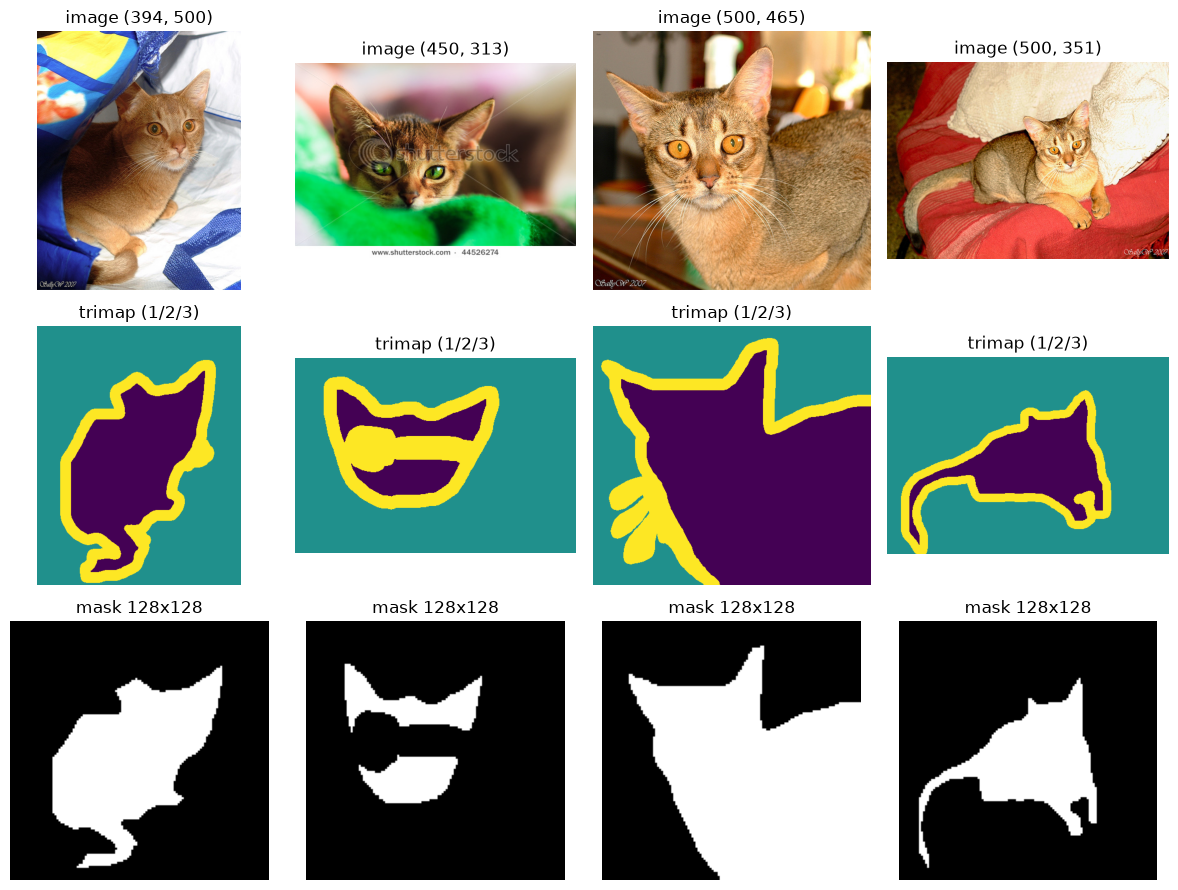

In [2]:
import time, random
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from PIL import Image

torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 데이터 내려받기 (약 800MB, 처음 한 번만)
raw_train = datasets.OxfordIIITPet("data", split="trainval", target_types="segmentation", download=True)
raw_test  = datasets.OxfordIIITPet("data", split="test",     target_types="segmentation", download=True)
print(f"원본: 학습 {len(raw_train)}장, 시험 {len(raw_test)}장 | 품종 {len(raw_train.classes)}종")

# trimap(1=반려동물, 2=배경, 3=경계) → 0/1 마스크로 바꾸는 함수
def trimap_to_mask(trimap):
    # ───────────── your code here ─────────────
    # trimap(PIL 이미지)을 numpy 배열로 바꾸고, 값이 1(반려동물)인 픽셀만 1.0, 나머지는 0.0인 float32 배열을 반환하세요
    # 힌트: (배열 == 1).astype(np.float32)
    return (np.array(trimap) == 1).astype(np.float32)
    # ─────────────────────────────────────────

# Dataset 정의
class PetSegDataset(Dataset):
    def __init__(self, raw, n=None, size=IMG_SIZE):
        n = len(raw) if n is None else min(n, len(raw))
        self.images, self.masks = [], []
        t0 = time.time()
        for i in range(n):
            img, trimap = raw[i]
            # ───────────── your code here ─────────────
            # img와 trimap을 (size, size)로 줄이세요. 사진은 Image.BILINEAR, 마스크(trimap)는 Image.NEAREST를 쓰는 이유를 생각해 보세요
            img = img.convert("RGB").resize((size, size), Image.BILINEAR)
            trimap = trimap.resize((size, size), Image.NEAREST)
            # ─────────────────────────────────────────
            self.images.append(np.array(img, dtype=np.float32) / 255.0)   # (H,W,3), 0~1
            self.masks.append(trimap_to_mask(trimap))                      # (H,W), 0/1
        print(f"  {n}장 전처리 완료 ({time.time() - t0:.0f}초)")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        # ───────────── your code here ─────────────
        # 교재 [프로그램 5-6]의 __getitem__처럼 (입력 텐서, 정답 텐서)를 반환하세요
        # 입력: self.images[idx] (H,W,3) → torch.tensor → (3,H,W)로 축 순서 바꾸기 (.permute(2, 0, 1))
        # 정답: self.masks[idx] (H,W) → torch.tensor
        x = torch.tensor(self.images[idx]).permute(2, 0, 1)
        y = torch.tensor(self.masks[idx])
        return x, y
        # ─────────────────────────────────────────

train_set = PetSegDataset(raw_train, N_TRAIN)
test_set  = PetSegDataset(raw_test, N_TEST)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_set, batch_size=BATCH_SIZE)

x, y = train_set[0]
print("입력 모양:", tuple(x.shape), "| 정답 모양:", tuple(y.shape), "| 정답 값:", torch.unique(y).tolist())
print(f"정답에서 반려동물 픽셀 비율: {y.mean():.2f}")

# 샘플 몇 장 보기: 사진 / trimap / 0-1 마스크
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for j in range(4):
    img_pil, trimap_pil = raw_train[j]
    axes[0, j].imshow(img_pil); axes[0, j].set_title(f"image {img_pil.size}"); axes[0, j].axis("off")
    axes[1, j].imshow(np.array(trimap_pil), cmap="viridis"); axes[1, j].set_title("trimap (1/2/3)"); axes[1, j].axis("off")
    xi, yi = train_set[j]
    axes[2, j].imshow(yi, cmap="gray"); axes[2, j].set_title(f"mask {IMG_SIZE}x{IMG_SIZE}"); axes[2, j].axis("off")
plt.tight_layout(); plt.show()

## [B-2] U-Net 모델 직접 구성하기 (교재 [프로그램 5-7] 대응)

교재의 `UNetMini`는 **풀링 1번**짜리였습니다: enc1 → pool → enc2 → 업샘플 → `torch.cat`(스킵 연결) → dec1 → 1×1 conv → sigmoid.
이 노트북에서는 같은 부품(합성곱 2개 묶음 `double_conv`, `MaxPool2d`, `F.interpolate`, `torch.cat`)으로
**U-Net을 직접 설계**합니다. **몇 단계까지 깊게 쌓을지(풀링 횟수)는 여러분이 정합니다.**

```
입력 (3, S, S)
 ├ enc1 (C) ───────────────────────────────── cat ─ dec1 (C) ─ 1×1 conv ─ sigmoid → (1, S, S)
 │  pool ↓                                      ↑ ×2
 ├ enc2 (2C) ────────────────── cat ─ dec2 (2C) ┘
 │  pool ↓                        ↑ ×2
 ├ enc3 (4C) ─────── cat ─ dec3 (4C)
 │  pool ↓            ↑ ×2
 └ ...  (얼마나 더 내려갈지는 여러분의 선택. 가장 깊은 단계가 bottleneck)
```

**설계 조건**
- 입력 `(B, 3, S, S)` → 출력 `(B, 1, S, S)`, 마지막은 `sigmoid`로 픽셀마다 확률을 냅니다.
- 첫 단계 채널은 `BASE_CH`(C), 한 단계 내려갈 때마다 채널 2배·크기 절반. 올라올 때는 반대.
- `USE_SKIP=True`면 같은 단계의 인코더 출력을 `torch.cat`으로 이어 붙입니다 (교재의 24 = 8 + 16 과 같은 채널 계산). `False`면 이어 붙이지 않습니다.
- `IMG_SIZE`는 2^(풀링 횟수)로 나누어떨어져야 합니다 (128이면 최대 7번).
- `USE_BN=True`면 `double_conv` 안에서 합성곱마다 `BatchNorm2d`가 들어갑니다 (교재 모델에는 없음).

**서술형 과제에서 물어볼 것**
- 내가 만든 U-Net의 **인코더-디코더 그림**: 위 그림처럼 단계별로 그리되, 각 단계의 출력 모양 `(채널, 높이, 너비)`와 스킵 연결(cat)의 채널 합을 적습니다.
- 왜 그 깊이로 정했는지, 그리고 깊이를 한 단계 늘리거나 줄였을 때 **파라미터 수**(아래 셀이 출력)와 IoU가 어떻게 달라지는지.
  깊이를 바꿔 가며 실행해 보고 숫자를 기록해 두세요.

In [3]:
import torch.nn as nn
import torch.nn.functional as F

def double_conv(in_ch, out_ch, use_bn=USE_BN):
    # 교재의 enc1/enc2/dec1과 같은 "합성곱 3×3 → ReLU" 두 번 묶음 (BN은 선택)
    layers = []
    for i, o in [(in_ch, out_ch), (out_ch, out_ch)]:
        layers.append(nn.Conv2d(i, o, 3, padding=1))
        if use_bn:
            layers.append(nn.BatchNorm2d(o))
        layers.append(nn.ReLU(inplace=True))
    return nn.Sequential(*layers)

class UNet(nn.Module):
    def __init__(self, in_ch=3, base=BASE_CH, use_skip=USE_SKIP):
        super().__init__()
        C = base
        self.use_skip = use_skip

        # ───────────── your code here ─────────────
        # 층을 정의하세요. 깊이(풀링 횟수)는 스스로 정합니다 (교재 UNetMini는 1번, 위 그림은 3번까지 예시)
        # 인코더: double_conv(in_ch→C), double_conv(C→2C), ... 한 단계마다 채널 2배. 가장 깊은 단계가 bottleneck
        # self.pool = nn.MaxPool2d(2)
        # 디코더: 단계마다 double_conv(입력 채널 → 그 단계의 인코더 채널). 입력 채널 = 올라온 채널 + (use_skip이면 그 단계 인코더 채널, 아니면 0) ← 교재의 24 = 8 + 16
        # 마지막 self.final = nn.Conv2d(C, 1, 1)
        assert IMG_SIZE % (2 ** N_POOL) == 0, "IMG_SIZE는 2**N_POOL로 나누어떨어져야 합니다"
        chs = [C * 2 ** k for k in range(N_POOL + 1)]          # 예) N_POOL=3: [16, 32, 64, 128]

        # 인코더: enc[0]=in_ch→C, enc[k]=chs[k-1]→chs[k] (마지막이 bottleneck)
        self.encoders = nn.ModuleList(
            [double_conv(in_ch, chs[0])] +
            [double_conv(chs[k - 1], chs[k]) for k in range(1, N_POOL + 1)]
        )
        self.pool = nn.MaxPool2d(2)

        # 디코더: 깊은 단계부터. 단계 k에서 올라온 채널 chs[k+1] + 스킵 chs[k] → chs[k]
        self.decoders = nn.ModuleList()
        for k in reversed(range(N_POOL)):
            dec_in = chs[k + 1] + (chs[k] if use_skip else 0)
            self.decoders.append(double_conv(dec_in, chs[k]))

        self.final = nn.Conv2d(C, 1, 1)
        # ─────────────────────────────────────────

    def up_and_merge(self, x, skip):
        # ───────────── your code here ─────────────
        # x를 F.interpolate로 2배 키우세요 (scale_factor=2, mode="bilinear", align_corners=False)
        # self.use_skip이 True면 torch.cat([skip, x], dim=1)을, 아니면 x를 그대로 반환하세요 (교재 [프로그램 5-7]의 업샘플링 + 잔차 연결)
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        if self.use_skip:
            return torch.cat([skip, x], dim=1)
        return x
        # ─────────────────────────────────────────

    def forward(self, x):
        # ───────────── your code here ─────────────
        # 순전파를 쓰세요
        # 인코더: 첫 단계는 그대로, 그 다음부터는 pool → double_conv. 각 단계의 출력을 스킵 연결용으로 남겨 두세요
        # 디코더: 가장 깊은 출력부터 up_and_merge(올라온 것, 같은 단계 인코더 출력) → double_conv 를 반복
        # 마지막에 self.final을 지나 torch.sigmoid를 적용한 (B,1,S,S)를 반환
        skips = []
        for k, enc in enumerate(self.encoders):
            if k > 0:
                x = self.pool(x)
            x = enc(x)
            skips.append(x)

        x = skips.pop()                                # bottleneck 출력
        for dec in self.decoders:
            x = dec(self.up_and_merge(x, skips.pop()))

        return torch.sigmoid(self.final(x))
        # ─────────────────────────────────────────

model = UNet().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"U-Net 파라미터 수: {n_params:,}  (N_POOL={N_POOL}, BASE_CH={BASE_CH}, USE_SKIP={USE_SKIP}, USE_BN={USE_BN})  ← 보고서에 깊이와 함께 기록하세요")

# 모양 확인: 입력 (2,3,S,S) → 출력 (2,1,S,S)
with torch.no_grad():
    out = model(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=device))
print("출력 모양:", tuple(out.shape))

U-Net 파라미터 수: 488,705  (N_POOL=3, BASE_CH=16, USE_SKIP=True, USE_BN=True)  ← 보고서에 깊이와 함께 기록하세요


출력 모양: (2, 1, 128, 128)


## [B-3] 손실 함수와 옵티마이저 설정 (교재 [프로그램 5-8] 대응)

교재와 같이 **픽셀 단위 이진 분류**이므로 `BCELoss`(이진 교차 엔트로피)를 씁니다.
손실값만으로는 "얼마나 잘 겹치는지"를 알기 어려우므로, 분할에서 흔히 쓰는 **IoU**(교집합/합집합)를 평가 지표로 추가합니다.

In [4]:
# ───────────── your code here ─────────────
# 교재 [프로그램 5-8]처럼 손실 함수 criterion(BCELoss)과 옵티마이저 optimizer(Adam, 학습률 LR)를 만드세요
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
# ─────────────────────────────────────────

def iou_score(pred_prob, target, threshold=0.5, eps=1e-6):
    # pred_prob, target: (B,H,W). 확률을 0.5 기준으로 0/1로 바꾼 뒤 이미지별 IoU 평균
    # ───────────── your code here ─────────────
    # pred_prob를 threshold 기준으로 0/1 float 텐서 pred로 바꾸세요
    # 이미지별 교집합 = (pred * target).sum(dim=(1, 2)), 합집합 = ((pred + target) > 0).float().sum(dim=(1, 2))
    # (교집합 + eps) / (합집합 + eps) 의 평균을 .item()으로 반환하세요
    pred = (pred_prob > threshold).float()
    inter = (pred * target).sum(dim=(1, 2))
    union = ((pred + target) > 0).float().sum(dim=(1, 2))
    return ((inter + eps) / (union + eps)).mean().item()
    # ─────────────────────────────────────────

def evaluate(model, loader):
    model.eval()
    total_loss, total_iou, n = 0.0, 0.0, 0
    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            preds = model(images).squeeze(1)
            total_loss += criterion(preds, masks).item() * len(images)
            total_iou += iou_score(preds, masks) * len(images)
            n += len(images)
    return total_loss / n, total_iou / n

print("학습 전 시험 손실/IoU:", tuple(round(v, 4) for v in evaluate(model, test_loader)))

학습 전 시험 손실/IoU: (0.6862, 0.0)


## [B-4] 학습 루프 실행하기 (교재 [프로그램 5-9] 대응)

교재의 루프와 같은 구조(`zero_grad → forward → loss → backward → step`)입니다.
다른 점은 (1) 텐서를 GPU로 옮기고, (2) 에폭마다 시험 데이터의 손실과 IoU를 기록한다는 것입니다.

In [5]:
history = {"train_loss": [], "test_loss": [], "test_iou": []}
t0 = time.time()

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)   # images: (B,3,S,S), masks: (B,S,S)

        # ───────────── your code here ─────────────
        # 교재 [프로그램 5-9]와 같은 다섯 단계를 쓰세요
        # 1) 기울기 초기화 2) preds = model(images).squeeze(1) → (B,S,S) 3) loss = criterion(preds, masks) 4) 역전파 5) 파라미터 갱신
        optimizer.zero_grad()
        preds = model(images).squeeze(1)
        loss = criterion(preds, masks)
        loss.backward()
        optimizer.step()
        # ─────────────────────────────────────────

        total_loss += loss.item() * len(images)

    train_loss = total_loss / len(train_set)
    test_loss, test_iou = evaluate(model, test_loader)
    history["train_loss"].append(train_loss); history["test_loss"].append(test_loss); history["test_iou"].append(test_iou)
    print(f"Epoch {epoch + 1}/{EPOCHS}  train loss {train_loss:.4f} | test loss {test_loss:.4f} | test IoU {test_iou:.4f}  ({time.time() - t0:.0f}s)")

print(f"학습 끝: 최종 test IoU {history['test_iou'][-1]:.4f}, 총 {time.time() - t0:.0f}초")

Epoch 1/5  train loss 0.4469 | test loss 0.4218 | test IoU 0.5641  (8s)


Epoch 2/5  train loss 0.3110 | test loss 0.3464 | test IoU 0.6219  (16s)


Epoch 3/5  train loss 0.2690 | test loss 0.2995 | test IoU 0.6465  (24s)


Epoch 4/5  train loss 0.2483 | test loss 0.3240 | test IoU 0.6268  (32s)


Epoch 5/5  train loss 0.2309 | test loss 0.2536 | test IoU 0.6425  (40s)
학습 끝: 최종 test IoU 0.6425, 총 40초


## [B-5] 학습 곡선 그리기 (추가)

에폭에 따른 손실과 IoU의 변화를 그립니다. 학습 손실만 계속 내려가고 시험 손실이 올라가면 과적합의 신호입니다.

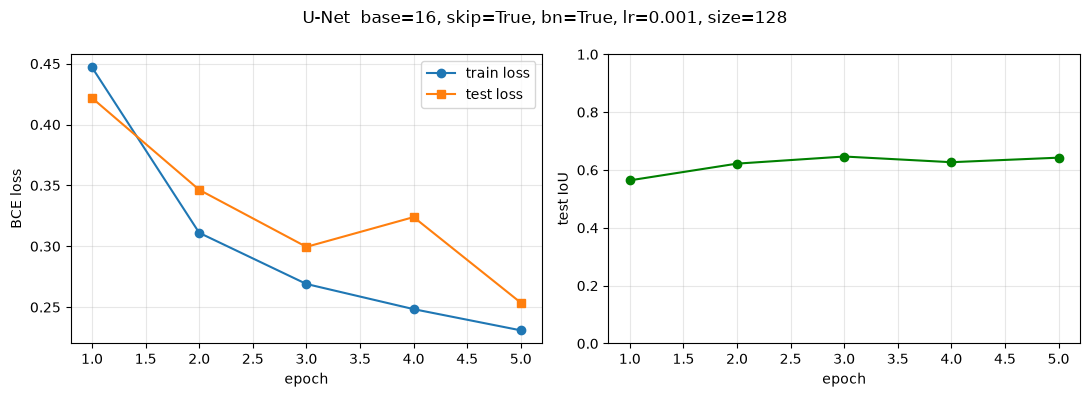

In [6]:
ep = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ep, history["train_loss"], "o-", label="train loss")
axes[0].plot(ep, history["test_loss"], "s-", label="test loss")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("BCE loss"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(ep, history["test_iou"], "o-", color="green")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("test IoU"); axes[1].set_ylim(0, 1); axes[1].grid(alpha=0.3)
fig.suptitle(f"U-Net  base={BASE_CH}, skip={USE_SKIP}, bn={USE_BN}, lr={LR}, size={IMG_SIZE}")
plt.tight_layout(); plt.show()

## [B-6] 분할 결과 시각화하기 (교재 [프로그램 5-10] 대응)

교재처럼 **Input / Target / Prediction** 을 나란히 그립니다. 예측은 0~1 확률 지도이므로,
0.5 기준으로 자른 0/1 마스크와 그때의 IoU도 함께 보여 줍니다.

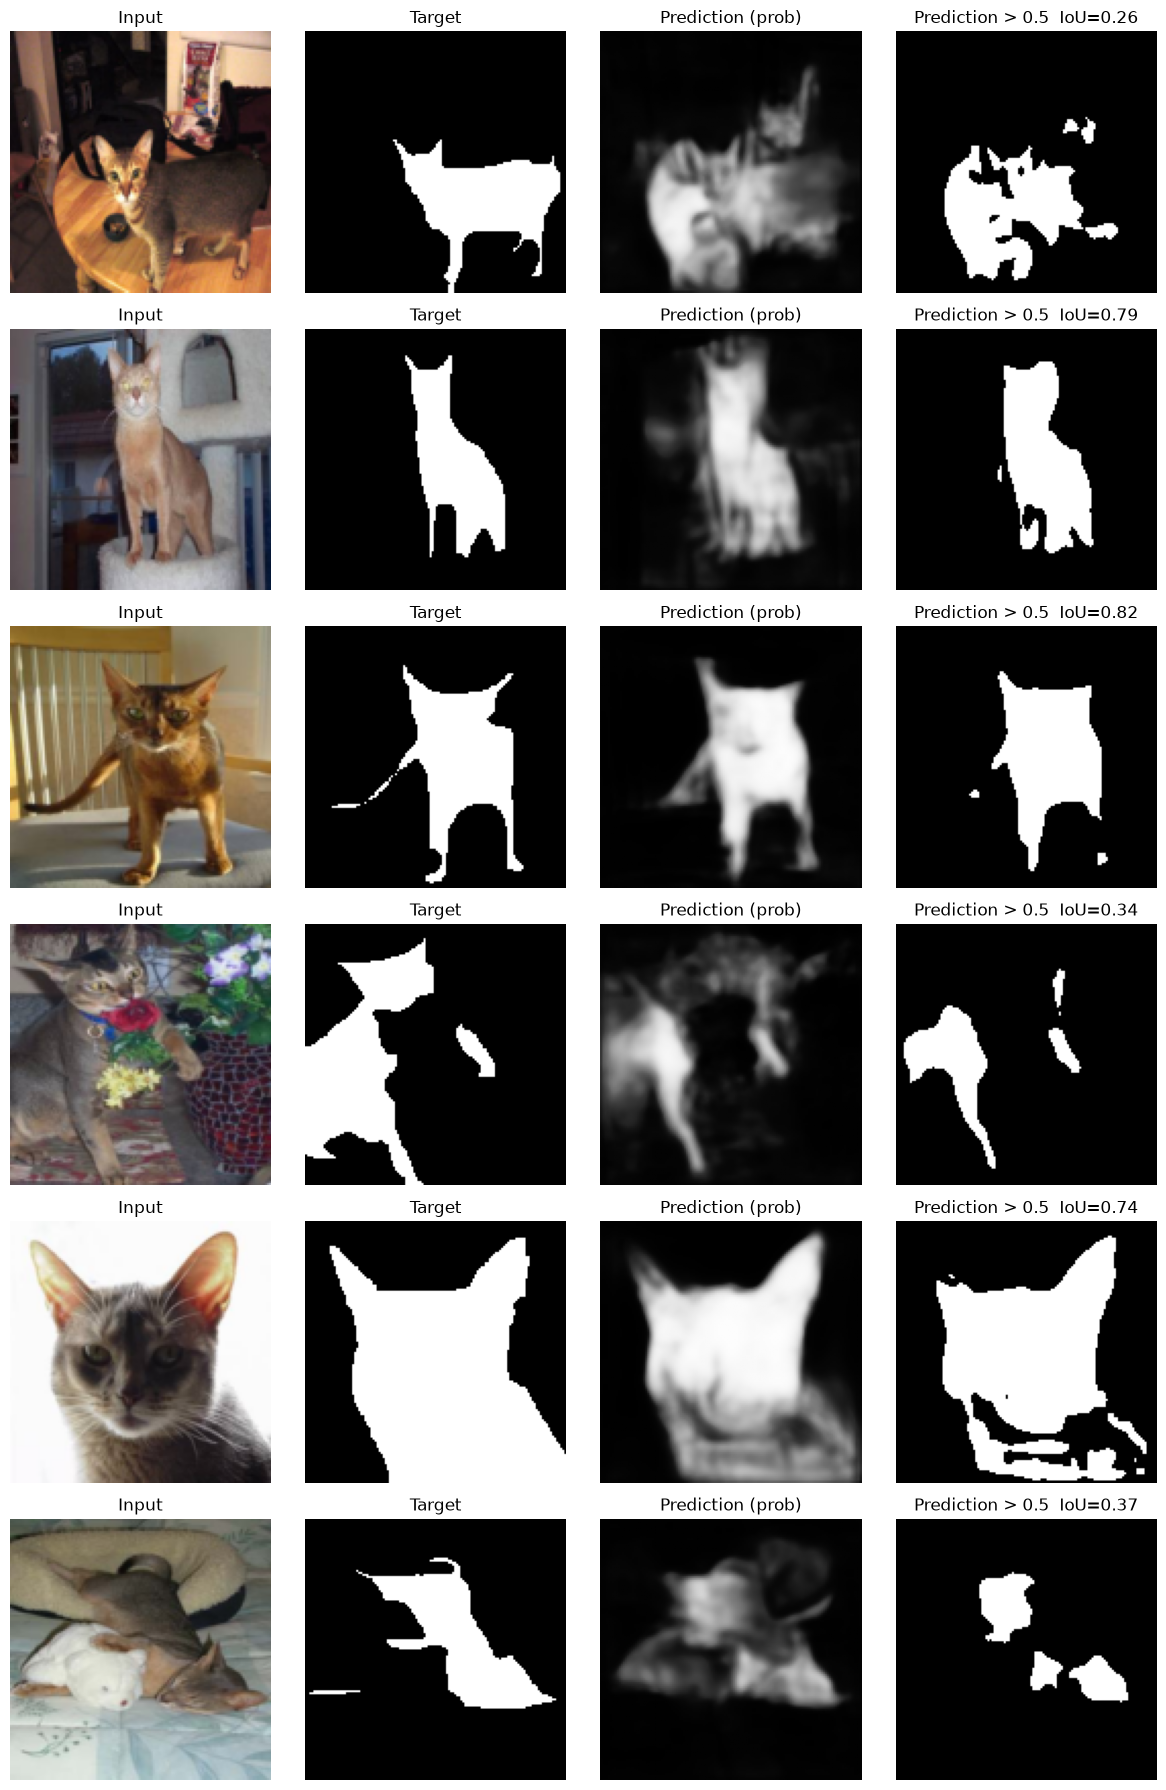

In [7]:
model.eval()
n_show = 6
fig, axes = plt.subplots(n_show, 4, figsize=(12, 3 * n_show))
for k in range(n_show):
    sample_img, sample_mask = test_set[k]
    # ───────────── your code here ─────────────
    # 교재 [프로그램 5-10]처럼 torch.no_grad() 안에서 예측하세요
    # sample_img (3,S,S)에 배치 축을 더해 (1,3,S,S)로 만들고 device로 옮겨 model에 넣은 뒤, .squeeze().cpu()로 (S,S) 확률 지도 pred를 만드세요
    with torch.no_grad():
        pred = model(sample_img.unsqueeze(0).to(device)).squeeze().cpu()
    # ─────────────────────────────────────────
    iou = iou_score(pred.unsqueeze(0), sample_mask.unsqueeze(0))
    axes[k, 0].imshow(sample_img.permute(1, 2, 0)); axes[k, 0].set_title("Input")
    axes[k, 1].imshow(sample_mask, cmap="gray"); axes[k, 1].set_title("Target")
    axes[k, 2].imshow(pred, cmap="gray", vmin=0, vmax=1); axes[k, 2].set_title("Prediction (prob)")
    axes[k, 3].imshow(pred > 0.5, cmap="gray"); axes[k, 3].set_title(f"Prediction > 0.5  IoU={iou:.2f}")
    for ax in axes[k]:
        ax.axis("off")
plt.tight_layout(); plt.show()

## [B-7] 내 사진으로 분할해 보기 (추가)

학습에 쓰지 않은 사진(반려동물 사진, 혹은 동물이 없는 사진)을 올려 모델이 어떻게 반응하는지 봅니다.
사진을 올리지 않으면 이 셀은 건너뜁니다.

사진: data/test.jpg | 0.5 넘는 픽셀 비율: 17.1% | 최대 확률: 0.98


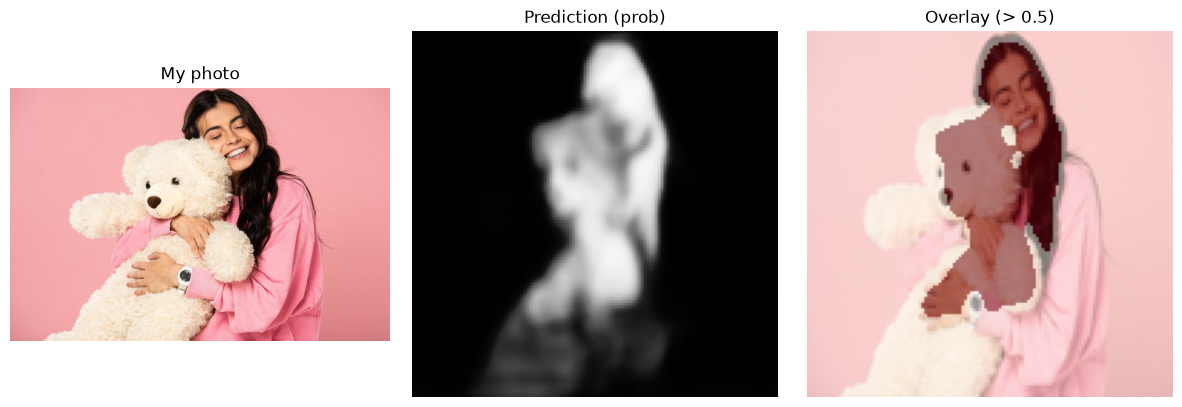

In [8]:
import os

MY_PHOTO_PATH = "data/test.jpg"   # 로컬에서 쓸 사진 경로. 없으면 Colab 업로드 창을 띄움

my_photo = MY_PHOTO_PATH if os.path.exists(MY_PHOTO_PATH) else None
if my_photo is None:
    try:
        from google.colab import files
        up = files.upload()
        if up:
            my_photo = list(up)[0]
    except Exception:
        pass

if my_photo is None:
    print("사진을 올리지 않아 건너뜁니다.")
else:
    pil = Image.open(my_photo).convert("RGB")
    x = torch.tensor(np.array(pil.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.float32) / 255.0).permute(2, 0, 1)
    with torch.no_grad():
        pred = model(x.unsqueeze(0).to(device)).squeeze().cpu()
    print(f"사진: {my_photo} | 0.5 넘는 픽셀 비율: {(pred > 0.5).float().mean():.1%} | 최대 확률: {pred.max():.2f}")
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(pil); axes[0].set_title("My photo")
    axes[1].imshow(pred, cmap="gray", vmin=0, vmax=1); axes[1].set_title("Prediction (prob)")
    axes[2].imshow(pil.resize((IMG_SIZE, IMG_SIZE))); axes[2].imshow(pred > 0.5, alpha=0.5, cmap="Reds"); axes[2].set_title("Overlay (> 0.5)")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout(); plt.show()